# 10 — Compare image-model architectures

**Version 2 reporting boundary.** Primary ranking is unweighted mean outer-fold **ROC-AUC**; AP is secondary. An inner-validation pilot or uncertainty experiment has no five-fold estimate, so its ROC-AUC is explicitly exploratory. The saved image recipes, AP-selected checkpoints/epochs and AP-based admission gates remain unchanged and are labelled historical selection rules. This is a presentation migration, not a ROC-selected image refit. Executing every cell reads saved artifacts and writes only new v2 reports: no image smoke, checkpoint inference, training, calibration fitting, cutoff selection, final all-development fit or reserved-test access occurs. The added metadata experiment uses its own explicit v2 ROC selection identity.

Does changing the image network improve early ranking at an affordable cost?
This notebook compares pretrained convolutional neural networks on matching
patients: **EfficientNet-B0** is a compact reference; **DenseNet121** passes
earlier features to later layers; **ConvNeXt-Tiny** uses a modernised convolutional
design. Different designs may learn useful patterns at different speeds.

An architecture is the network design; a **recipe** specifies how it is trained.
A **checkpoint** stores weights after an epoch (one pass through fitting data).
For each recipe, the highest validation AP checkpoint is reported.

These are **inner-validation diagnostics**: held-out fitting-pool patients guide
recipe and epoch choices. Full out-of-fold (OOF) evaluation would test the entire
selection process on independent outer patients. Outer fold 0 and the reserved
test are excluded here. Eight new fits were budgeted; the saved completion
ledger establishes what actually ran. Short pilots cannot eliminate a slower
family or select the final model.

Training defaults to disabled. The notebook reads executed results using shared
training/reporting utilities. See the [concept guide](../concepts.md) for terms.


In [2]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src/melanoma_detection").is_dir() and (path / "configs/image_model.yaml").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.image_evaluation import load_historical_pilot, load_architecture_outputs, metric_table, curve_tables, sha256
from melanoma_detection.image_reporting import (plot_learning_curves, plot_training_losses,
    plot_roc_precision_recall, plot_confusion_matrices, plot_resource_comparison,
    plot_raw_reliability, save_figure)

TRAIN_ARCHITECTURES = False
import yaml
from melanoma_detection.image_roc_reporting import report_directory, show_saved_figure, save_figure
config = yaml.safe_load((PROJECT_ROOT / "configs/image_architecture_pilot.yaml").read_text(encoding="utf-8"))
run_dir = PROJECT_ROOT / config["run"]["output_dir"] / config["run"]["run_id"]
historical = load_historical_pilot(PROJECT_ROOT)
summary_path = run_dir / "summary.json"
if not summary_path.is_file():
    raise FileNotFoundError("Prepare/run the shared architecture CLI first; this notebook does not fabricate results.")
summary = json.loads(summary_path.read_text(encoding="utf-8"))
bundle = load_architecture_outputs(PROJECT_ROOT, summary)
predictions, matched, history = bundle["predictions"], bundle["matched_predictions"], bundle["histories"]
all_records = [*summary.get("b0_reference", []), *summary.get("recipes", [])]
epochs = {record["pipeline_id"]: record.get("best_epoch") for record in all_records}
report_dir = report_directory(PROJECT_ROOT, "original", '10_image_architecture_comparison')
figures_dir, tables_dir = report_dir / "figures", report_dir / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "figure.facecolor": "white", "axes.facecolor": "white"})
print("Run:", summary["run_id"], "| status:", summary["status"], "| training enabled:", TRAIN_ARCHITECTURES)
print("Matched completed slots:", summary["matched_recipe_slots"])
print("Unmatched completed trials:", summary["unmatched_completed_trials"])
display(Markdown(summary["recommendation"]))

from melanoma_detection.image_roc_reporting import plot_resource_comparison


Run: architecture_pilot_3h_v1 | status: complete | training enabled: False
Matched completed slots: ['low_none', 'low_sqrt', 'high_none', 'high_sqrt']
Unmatched completed trials: []


Complete paused trials, then independently validate every family with longer training and three inner folds; short-pilot scores cannot eliminate a slower family.

## Shared preparation and the completion ledger

Every family uses the same patient memberships and whole RGB images resized
to 224 × 224 pixels, with the same weak fitting flips/rotation and ImageNet
colour normalisation. Ordinary validation has no random augmentation. These
controls make the network comparison easier to interpret.

Each family tries its own low/high backbone learning rates (the size of weight
updates), with either no class weighting or fitting-only square-root positive
weighting (more influence for rare malignant examples). Thus `low_sqrt` is a
matched recipe **slot**, not an identical numerical learning rate across networks.
Effective batch size is 64 images. Each admitted fit runs six epochs, including
one classifier-only warmup, under a fixed 30-epoch learning-rate schedule. The
selected epoch is the highest AP so far; exact ties retain the earlier epoch.

B0/DenseNet keep BatchNorm statistics and parameters fixed, limiting changes
to their pretrained normalisation with small image batches. ConvNeXt retains
its native LayerNorm, trained during full fine-tuning. All new classifiers use
dropout 0.2 and one logit, converted to a score between 0 and 1. The
[concept guide](../concepts.md) explains these terms.

Read `status` and `completed_epochs` before comparing results. Only completed
matching slots rank families; a paused trial is unfinished, not inferior. The
original session allowed at most 50 training minutes within its wider deadline.


In [3]:
ledger_rows = []
for record in all_records:
    ledger_rows.append({"pipeline_id": record["pipeline_id"], "family": record["architecture"],
        "recipe_slot": record["recipe_slot"], "status": record["status"],
        "completed_epochs": record.get("completed_epochs"), "selected_epoch": record.get("best_epoch"),
        "backbone_lr": record.get("backbone_lr"), "loss_weight": record.get("loss_weight"),
        "matched_comparison": record["recipe_slot"] in summary["matched_recipe_slots"]})
ledger = pd.DataFrame(ledger_rows)
ledger.to_csv(tables_dir / "completion_ledger.csv", index=False)
display(ledger)
display(pd.DataFrame(summary.get("runtime_estimates", {})).T)
print("Ordinary validation: deterministic | calibrated scores: unavailable | tuned thresholds: deferred")


,pipeline_id,family,recipe_slot,status,completed_epochs,selected_epoch,backbone_lr,loss_weight,matched_comparison
0,efficientnet_b0/low_none,efficientnet_b0,low_none,complete,6,5,NaN,NaN,True
1,efficientnet_b0/low_sqrt,efficientnet_b0,low_sqrt,complete,6,6,NaN,NaN,True
2,efficientnet_b0/high_none,efficientnet_b0,high_none,complete,6,4,NaN,NaN,True
3,efficientnet_b0/high_sqrt,efficientnet_b0,high_sqrt,complete,6,6,NaN,NaN,True
4,densenet121/low_none,densenet121,low_none,complete,6,2,0.00003,none,True
5,convnext_tiny/low_none,convnext_tiny,low_none,complete,6,6,0.00001,none,True
6,densenet121/low_sqrt,densenet121,low_sqrt,complete,6,6,0.00003,sqrt_ratio,True
7,convnext_tiny/low_sqrt,convnext_tiny,low_sqrt,complete,6,6,0.00001,sqrt_ratio,True
8,densenet121/high_none,densenet121,high_none,complete,6,4,0.00010,none,True
9,convnext_tiny/high_none,convnext_tiny,high_none,complete,6,6,0.00003,none,True


,measured_mean_epoch_seconds,measured_max_epoch_seconds,measured_epochs,peak_allocated_memory_bytes
densenet121,43.079217,46.140481,24.0,2.352355e+09
convnext_tiny,45.313949,55.085114,24.0,1.587335e+09


Ordinary validation: deterministic | calibrated scores: unavailable | tuned thresholds: deferred


**Read the preparation preview:** each row contains one fitting image; the
original is left and three seeded weak variants follow. `target=1` means melanoma,
`target=0` benign. Compare the full lesion boundary, texture and colour. Rotation
can create black corners or clip peripheral pixels. This small deliberate label
mix checks image preparation; it does not certify every lesion or represent
dataset prevalence. Later augmentation and lighting stages are separate.


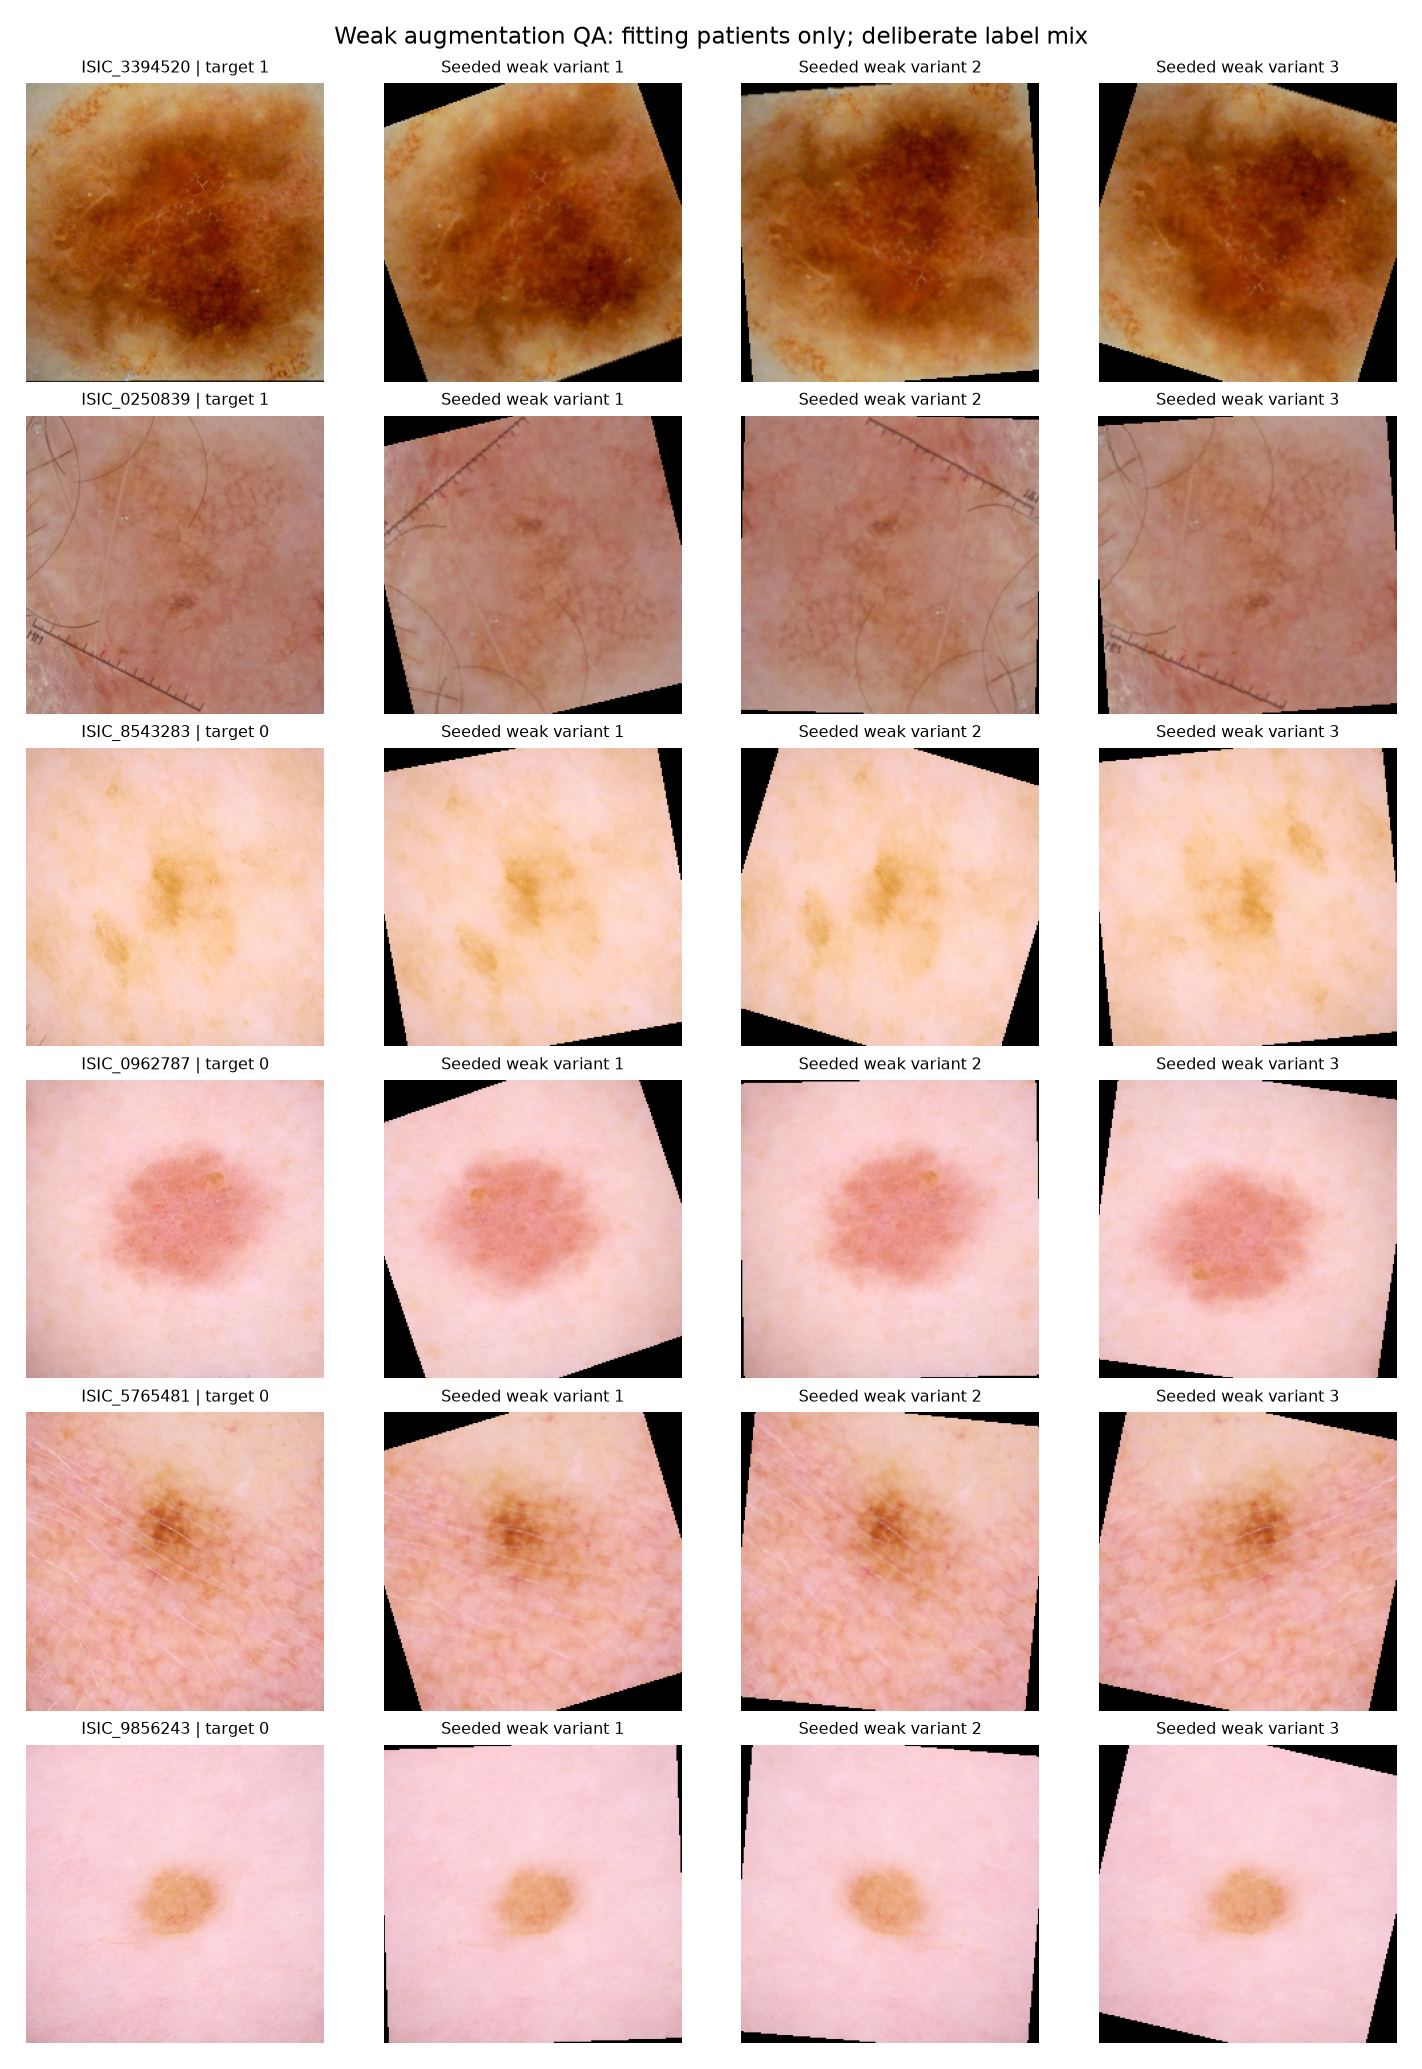

In [4]:
show_saved_figure(PROJECT_ROOT,"results/image_d1_runs/architecture_pilot_3h_v1/figures/weak_augmentation_preview.png")

## Learning over epochs

For each family, the first figure uses completed epoch horizontally and four
validation metrics vertically. Each line is a recipe; paused runs are labelled.
**AP** summarises precision across recall levels and is useful for rare melanoma;
**ROC-AUC** measures overall ranking. Higher is better for both; their guides
are malignant-image prevalence and chance AUC 0.5. **Log loss** penalises confident
wrong scores and **Brier** averages squared score errors; lower is better. A low
loss can still accompany poor melanoma detection, so read the ranking panels too.

Hollow rings mark the AP-selected epoch across all panels. The dotted vertical
line separates warmup from whole-network fine-tuning. The next figure plots
fitting BCE (binary cross-entropy, the training objective) against epoch, grouped
by weighting. Falling fitting loss should be checked against validation trends.
Weighted and unweighted fitting-loss magnitudes are not comparable. Six epochs
show early progress, not each family's full learning potential.


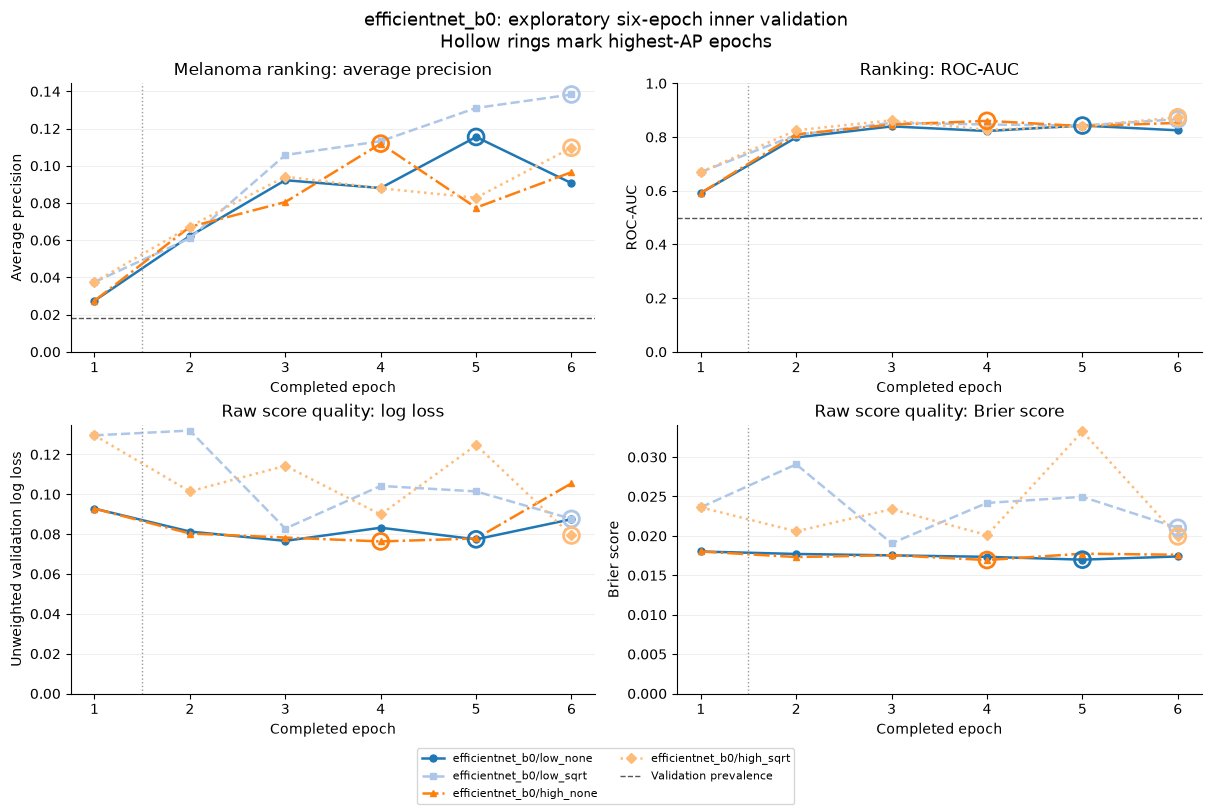

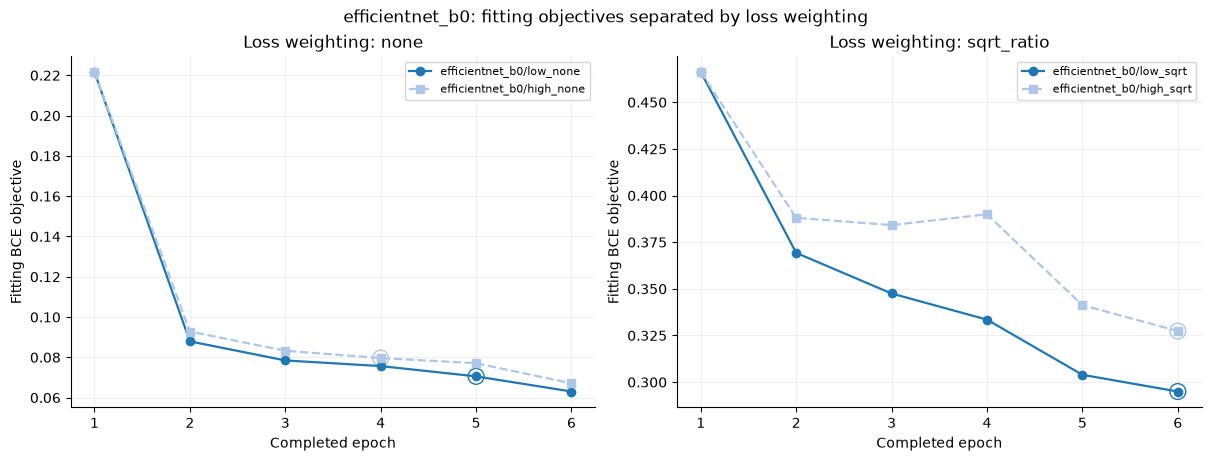

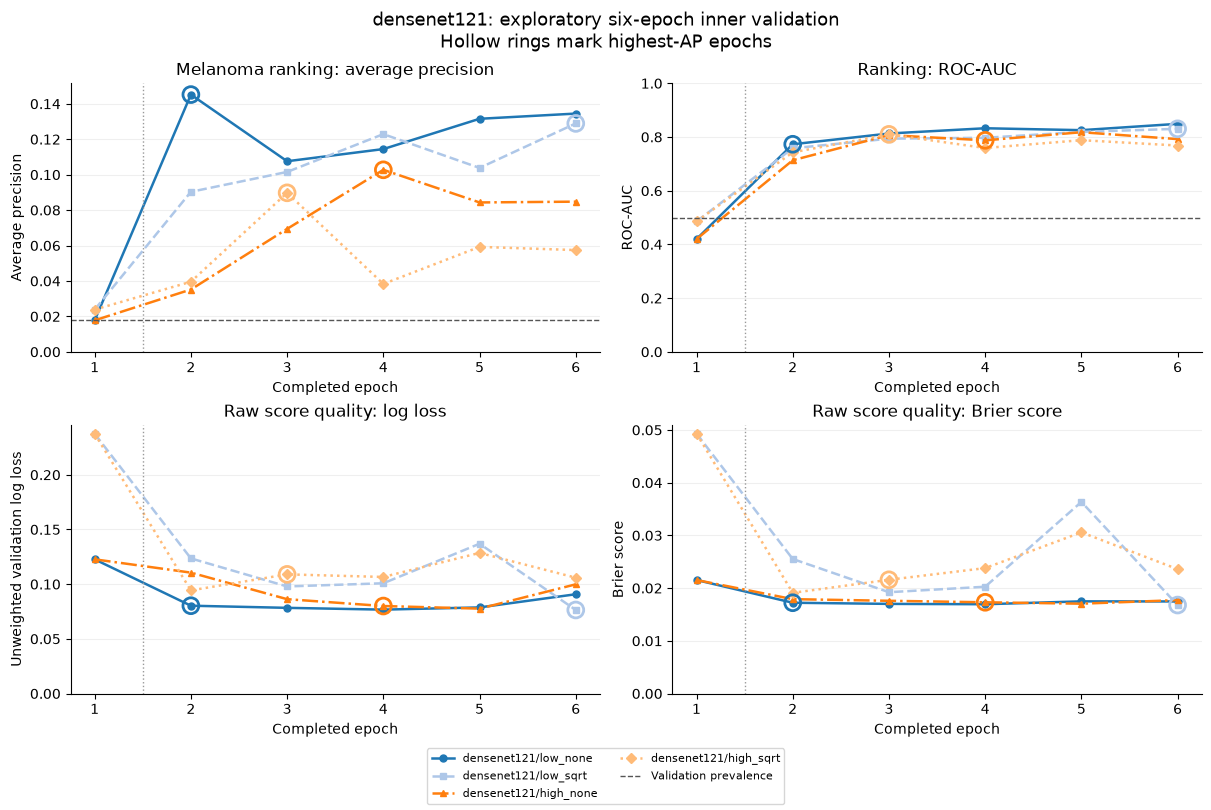

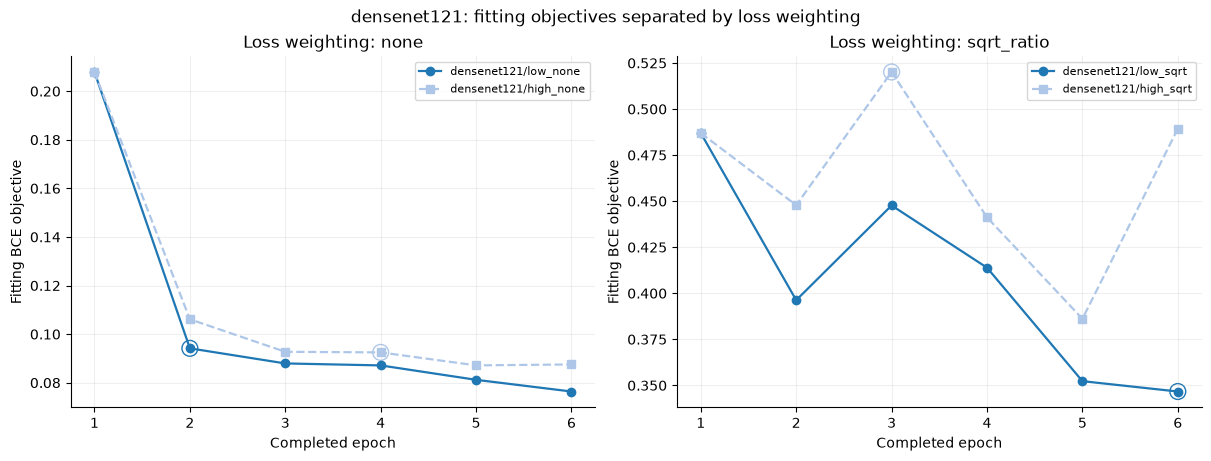

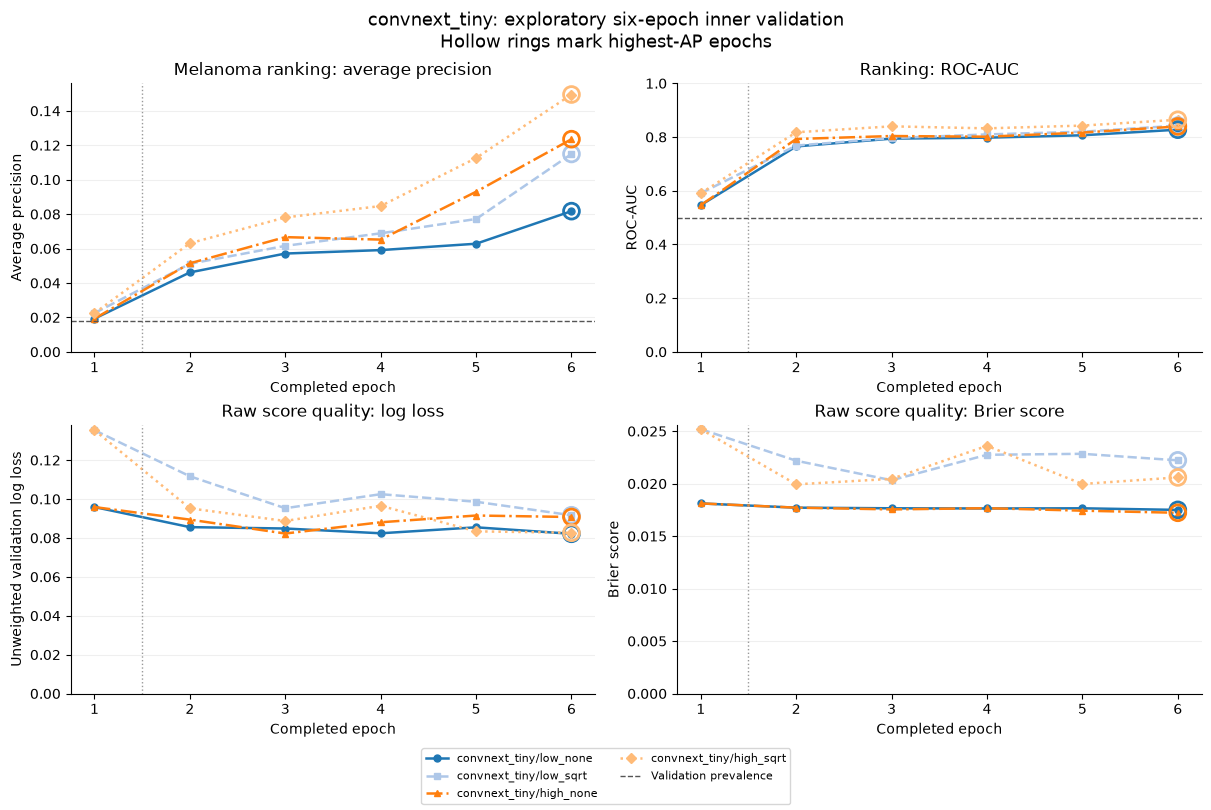

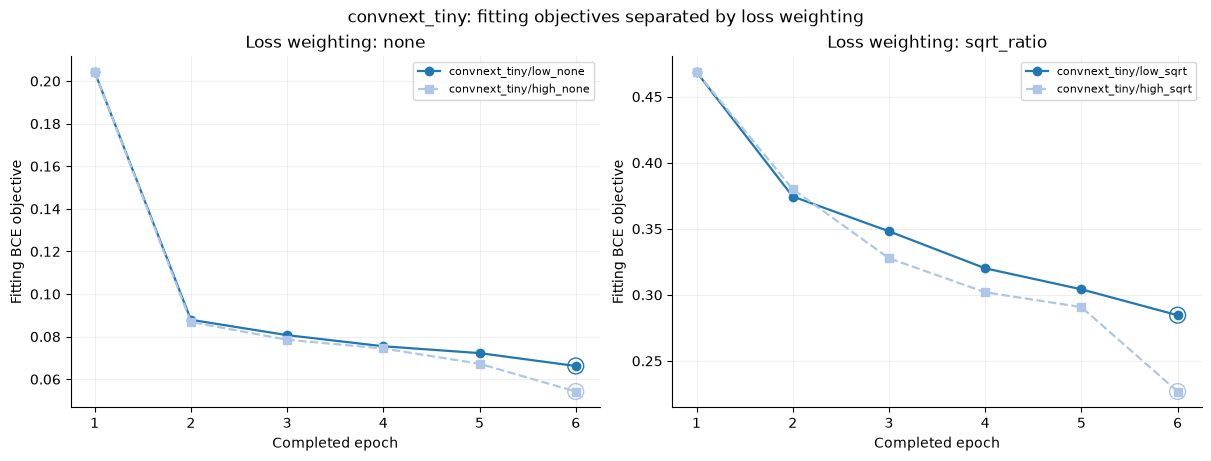

In [5]:
if not history.empty:
    for family, family_history in history.groupby("architecture", sort=False):
        fig = plot_learning_curves(family_history, historical["validation"].target.mean(),
            f"{family}: exploratory six-epoch inner validation")
        save_figure(fig, figures_dir / f"{family}_learning_curves.png")
        plt.show()
        loss = plot_training_losses(family_history, title=f"{family}: fitting objectives separated by loss weighting")
        save_figure(loss, figures_dir / f"{family}_training_loss.png")
        plt.show()
else:
    print("No completed trial histories available; no curves fabricated.")


## Compare completed matching recipes

Only slots completed for **all three families** enter these tables and plots.
All scores concern the same validation images and patients. ROC-AUC is primary;
log loss and Brier describe score errors, and AP supplies the secondary rare-positive ranking
view. Raw scores remain uncalibrated.

**Read the horizontal bars:** each row is a network/recipe. The three panels
show ROC-AUC at the historical AP-selected checkpoint (longer is better), total measured training minutes
and peak allocated GPU memory in GiB (shorter is cheaper). Time sums the recorded
epochs despite the figure's "epoch time" title and excludes downloads/setup;
memory is allocated by training, not total device usage. Assess the trade-off
without treating the small ranking difference as final evidence.

**Read each matched-slot curve pair:** each line is one family. The left ROC
panel plots benign false-positive rate horizontally against melanoma recall
vertically; nearer the upper left is better than the chance diagonal. The right
precision–recall panel plots recall horizontally against precision (malignancy
among flags) vertically; higher at the same recall is better. The horizontal
guide is prevalence. Moving along a curve changes the cutoff; the legend names
the selected epoch and metric. AP is not the trapezoidal area under the plotted
steps. No curve chooses a referral or classification cutoff here.


,pipeline_id,selected_epoch,roc_auc,average_precision,log_loss,brier,n_images,n_patients
0,efficientnet_b0/low_none,5,0.8426,0.1155,0.0774,0.0170,1834,113
1,efficientnet_b0/low_sqrt,6,0.8663,0.1383,0.0876,0.0210,1834,113
2,efficientnet_b0/high_none,4,0.8602,0.1119,0.0763,0.0169,1834,113
3,efficientnet_b0/high_sqrt,6,0.8734,0.1097,0.0793,0.0199,1834,113
4,densenet121/low_none,2,0.7730,0.1452,0.0803,0.0172,1834,113
5,convnext_tiny/low_none,6,0.8273,0.0817,0.0821,0.0175,1834,113
6,densenet121/low_sqrt,6,0.8305,0.1289,0.0764,0.0168,1834,113
7,convnext_tiny/low_sqrt,6,0.8423,0.1150,0.0917,0.0222,1834,113
8,densenet121/high_none,4,0.7876,0.1027,0.0800,0.0173,1834,113
9,convnext_tiny/high_none,6,0.8393,0.1235,0.0908,0.0172,1834,113


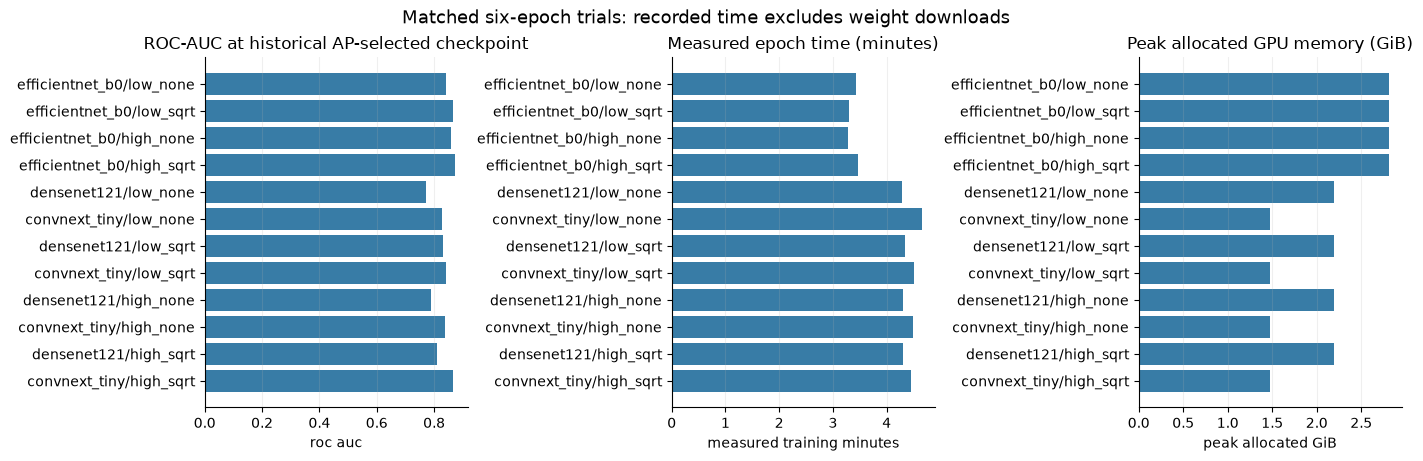

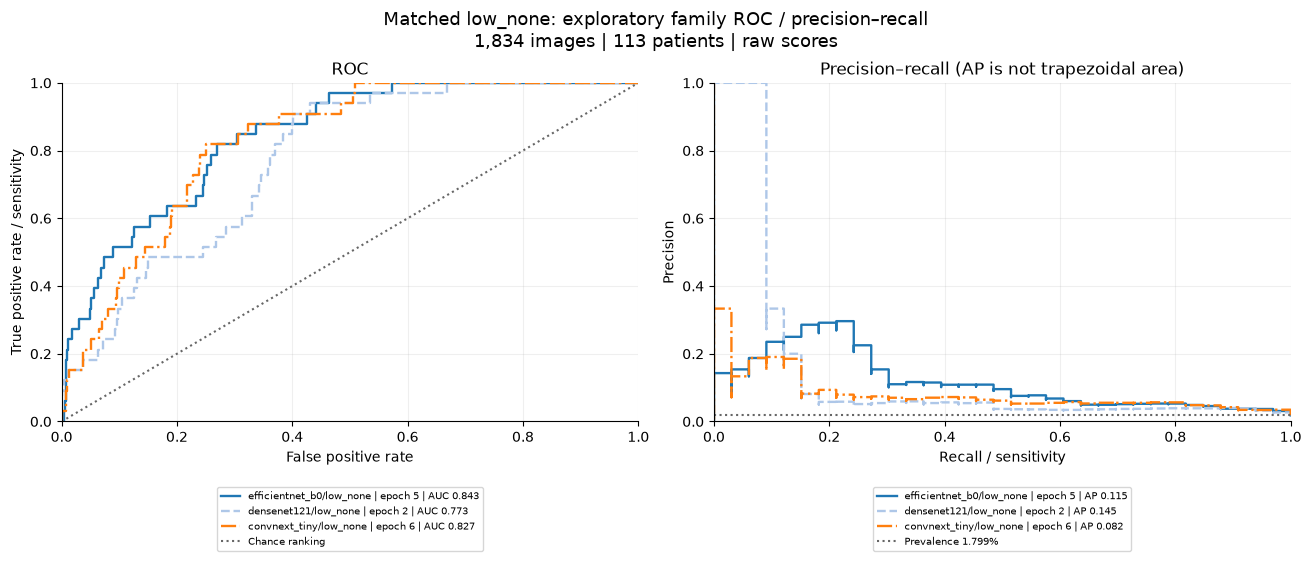

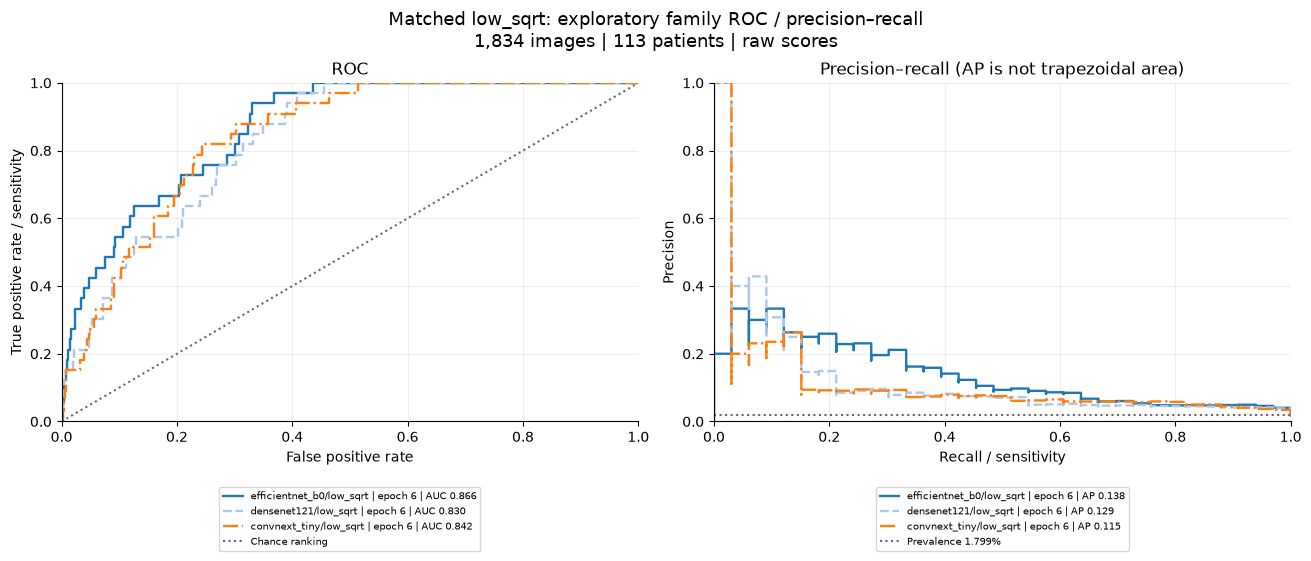

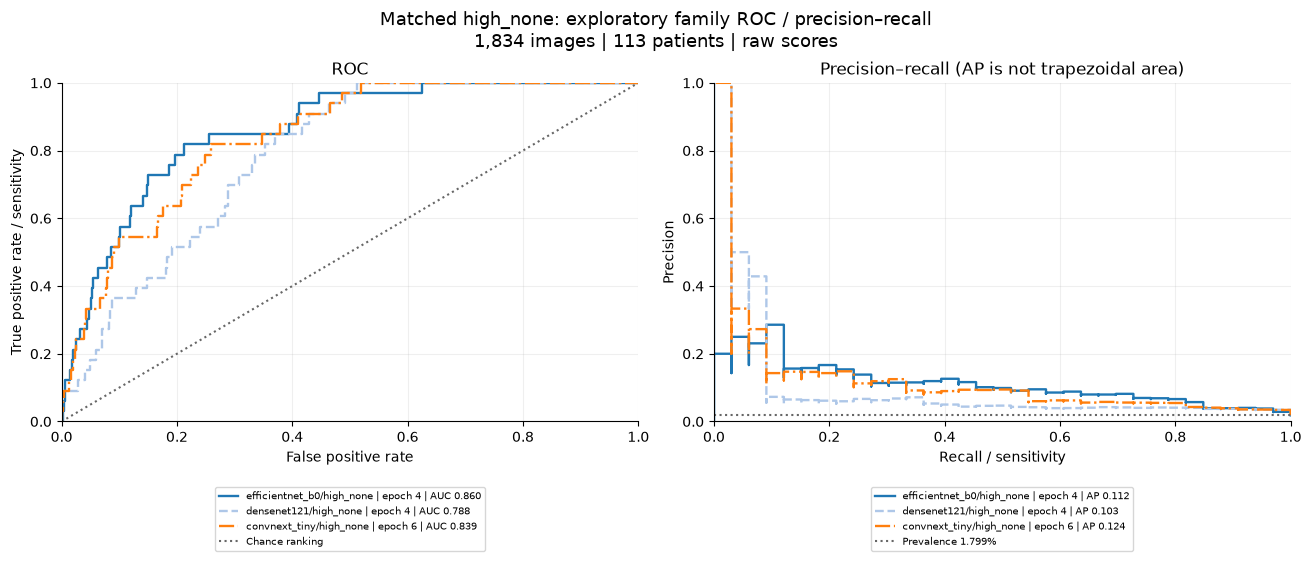

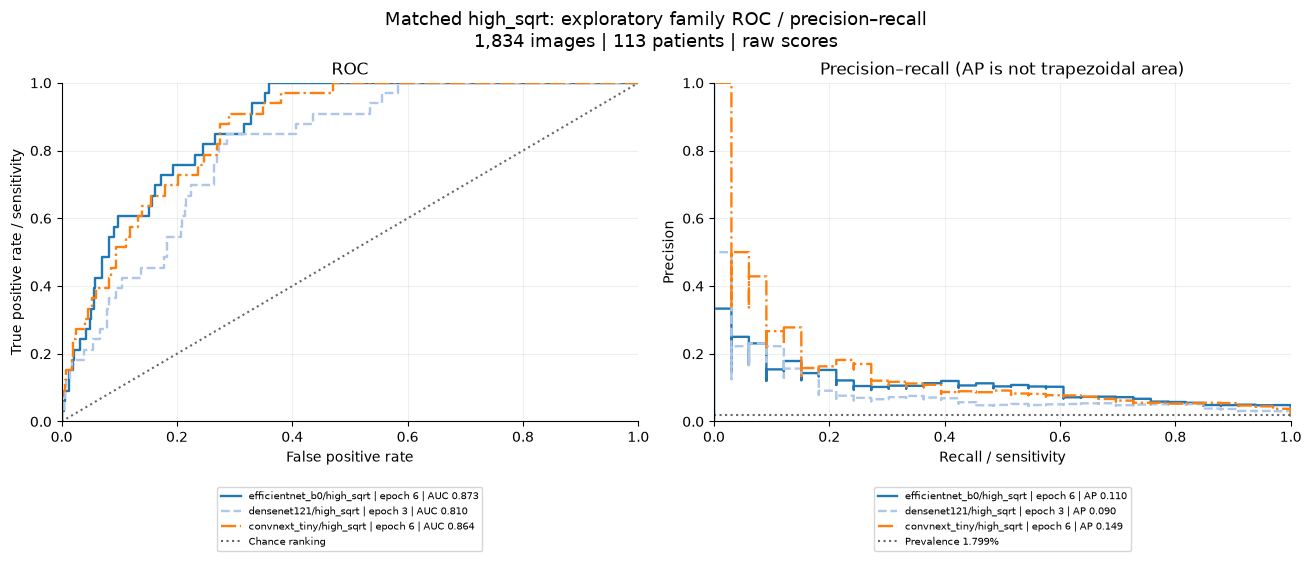

In [6]:
if matched:
    metrics = metric_table(matched, threshold=.5, epochs=epochs)
    metrics.to_csv(tables_dir / "matched_metrics_raw_threshold_0_5.csv", index=False)
    display(metrics[["pipeline_id", "selected_epoch", "roc_auc", "average_precision", "log_loss", "brier",
        "n_images", "n_patients"]].style.format({key: "{:.4f}" for key in
        ["roc_auc", "average_precision", "log_loss", "brier"]}))
    matched_history = history.loc[history.pipeline_id.isin(matched)]
    resource = plot_resource_comparison(matched_history, metrics)
    save_figure(resource, figures_dir / "matched_performance_time_memory.png")
    plt.show()
    for slot in summary["matched_recipe_slots"]:
        paired = {key: frame for key, frame in matched.items() if frame.recipe_slot.iloc[0] == slot}
        curves = plot_roc_precision_recall(paired, epochs=epochs,
            title=f"Matched {slot}: exploratory family ROC / precision–recall")
        save_figure(curves, figures_dir / f"{slot}_roc_precision_recall.png")
        plt.show()
        for identity, frame in paired.items():
            for name, table in curve_tables(frame.target, frame.base_probability).items():
                if isinstance(table, pd.DataFrame):
                    table.to_csv(tables_dir / f"{identity.replace('/', '__')}_{name}.csv", index=False)
else:
    print("No matched DenseNet/ConvNeXt/B0 slot completed; no family ranking reported.")


## Fixed-cutoff errors and descriptive reliability

Flag a raw score `>= 0.5`; the stored `base_probability` column is an uncalibrated
score despite its name. The cutoff is declared rather than fitted to these labels.
Recall/sensitivity measures malignant images found; specificity measures benign
images correctly unflagged. Precision measures malignancy among flags; F1
balances precision and recall. Undefined precision remains missing.

**Read the confusion matrices:** one panel per family, rows are true class and
columns predicted class. Diagonal cells are correct; bottom left is missed
melanoma, top right is benign images flagged. Text gives counts and percentages
within each true-class row; darker blue means a larger row fraction. Compare
missed malignancies and false alarms alongside AP.

**Read the reliability panels:** horizontal position is mean score in a bin;
vertical position is observed melanoma fraction. Points on the diagonal agree;
below it scores exceed the observed frequency, above it scores fall below it.
Panels share the observed-range axes and the table gives bin support. Few
malignant images and shared patients make bins noisy. This describes reliability
without fitting a calibrator or validating clinical risk. An 80%-recall cutoff
requires later training-only OOF predictions.


,pipeline_id,selected_epoch,threshold,score_type,TP,FP,TN,FN,precision,recall,sensitivity,specificity,f1
0,efficientnet_b0/low_none,5,0.500000,raw_base_probability,0,1,1800,33,0.0000,0.0000,0.0000,0.9994,0.0000
1,efficientnet_b0/low_sqrt,6,0.500000,raw_base_probability,4,14,1787,29,0.2222,0.1212,0.1212,0.9922,0.1569
2,efficientnet_b0/high_none,4,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000
3,efficientnet_b0/high_sqrt,6,0.500000,raw_base_probability,3,14,1787,30,0.1765,0.0909,0.0909,0.9922,0.1200
4,densenet121/low_none,2,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000
5,convnext_tiny/low_none,6,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000
6,densenet121/low_sqrt,6,0.500000,raw_base_probability,1,0,1801,32,1.0000,0.0303,0.0303,1.0000,0.0588
7,convnext_tiny/low_sqrt,6,0.500000,raw_base_probability,3,12,1789,30,0.2000,0.0909,0.0909,0.9933,0.1250
8,densenet121/high_none,4,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000
9,convnext_tiny/high_none,6,0.500000,raw_base_probability,0,0,1801,33,Undefined,0.0000,0.0000,1.0000,0.0000


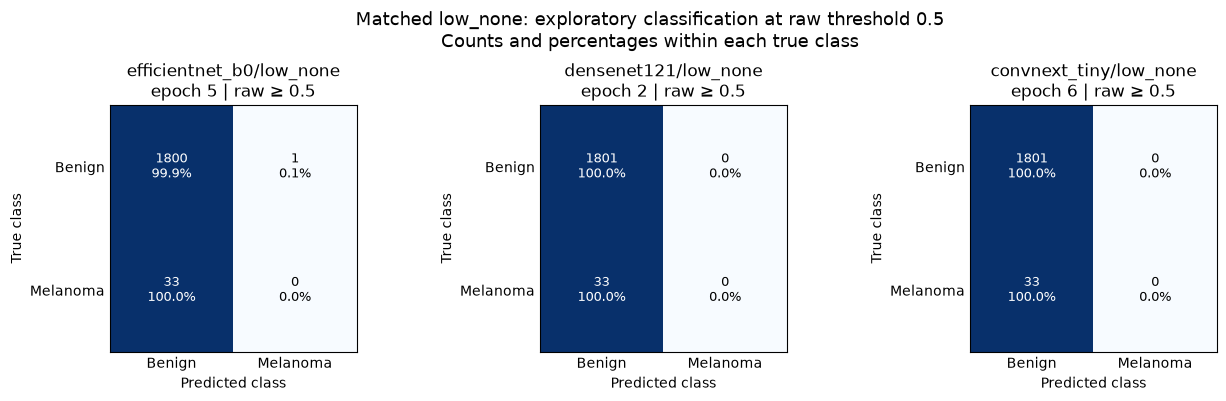

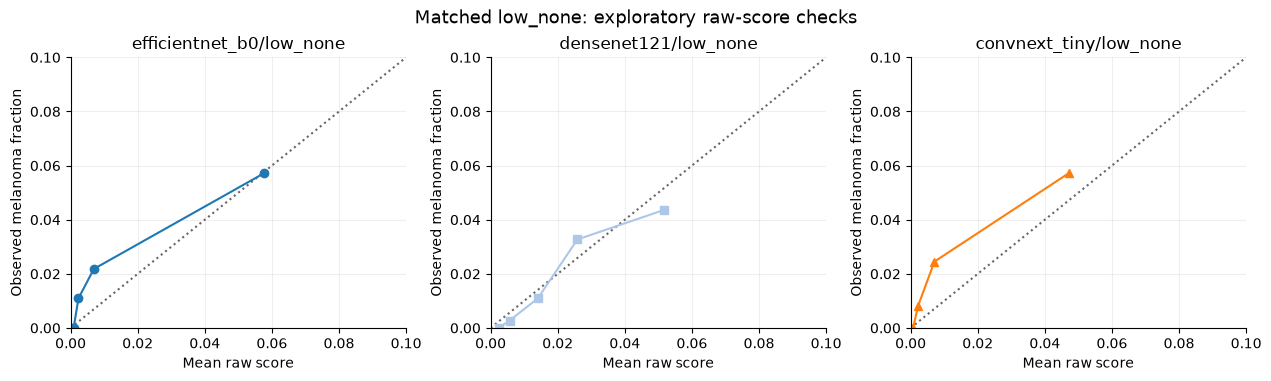

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,pipeline_id
0,1,367,0,0.000285,0.000000,0.000052,0.000517,47,efficientnet_b0/low_none
1,2,367,0,0.000890,0.000000,0.000518,0.001391,64,efficientnet_b0/low_none
2,3,366,4,0.002341,0.010929,0.001393,0.003656,77,efficientnet_b0/low_none
3,4,367,8,0.006916,0.021798,0.003667,0.012304,88,efficientnet_b0/low_none
4,5,367,21,0.057722,0.057221,0.012340,0.528130,91,efficientnet_b0/low_none
5,1,367,0,0.002408,0.000000,0.000867,0.003478,36,densenet121/low_none
6,2,367,1,0.005651,0.002725,0.003489,0.009030,56,densenet121/low_none
7,3,366,4,0.014062,0.010929,0.009050,0.019436,89,densenet121/low_none
8,4,367,12,0.025855,0.032698,0.019462,0.033319,93,densenet121/low_none
9,5,367,16,0.051669,0.043597,0.033376,0.129128,85,densenet121/low_none


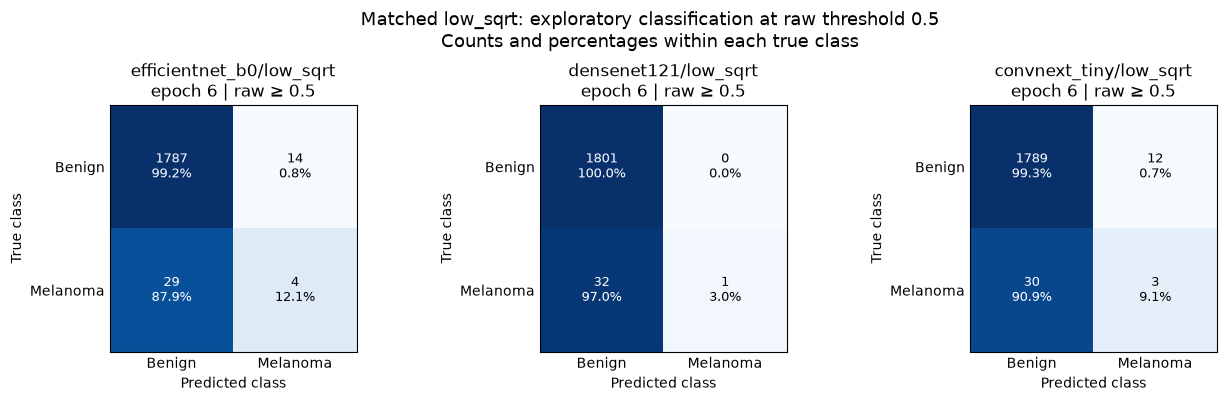

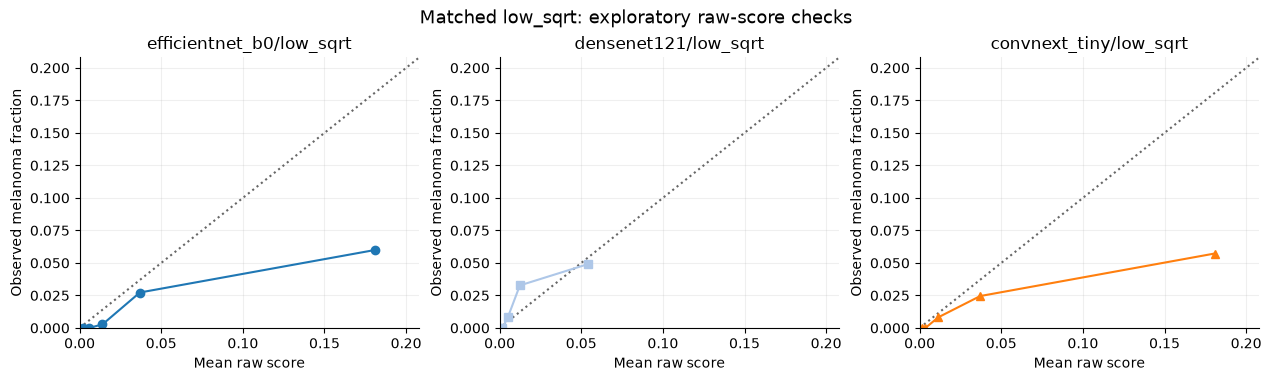

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,pipeline_id
0,1,367,0,0.002074,0.000000,0.000285,0.003629,45,efficientnet_b0/low_sqrt
1,2,367,0,0.005793,0.000000,0.003631,0.008343,63,efficientnet_b0/low_sqrt
2,3,366,1,0.014004,0.002732,0.008363,0.021968,88,efficientnet_b0/low_sqrt
3,4,367,10,0.036893,0.027248,0.022069,0.058213,94,efficientnet_b0/low_sqrt
4,5,367,22,0.180943,0.059946,0.058433,0.836534,92,efficientnet_b0/low_sqrt
5,1,367,0,0.000693,0.000000,0.000140,0.001075,46,densenet121/low_sqrt
6,2,367,0,0.001751,0.000000,0.001078,0.002714,60,densenet121/low_sqrt
7,3,366,3,0.005025,0.008197,0.002723,0.008061,88,densenet121/low_sqrt
8,4,367,12,0.012382,0.032698,0.008063,0.018460,90,densenet121/low_sqrt
9,5,367,18,0.054014,0.049046,0.018573,0.507202,93,densenet121/low_sqrt


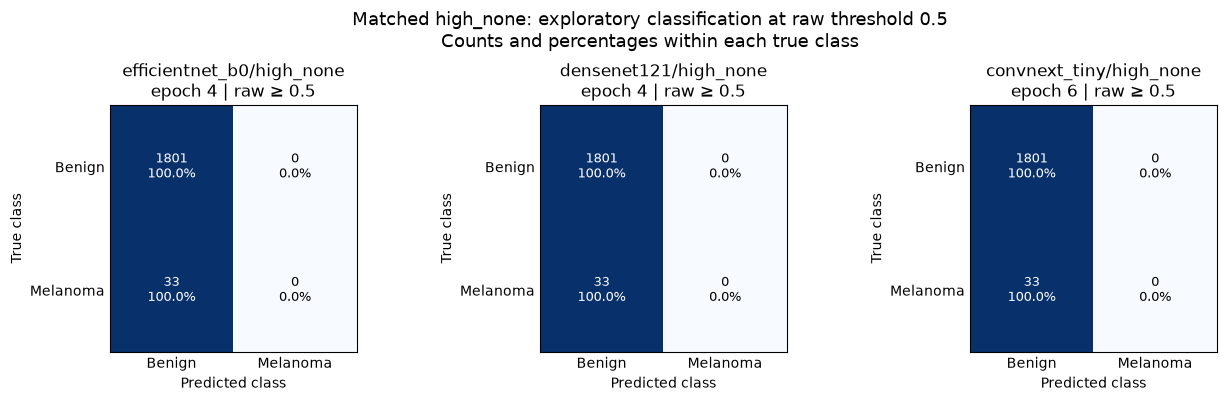

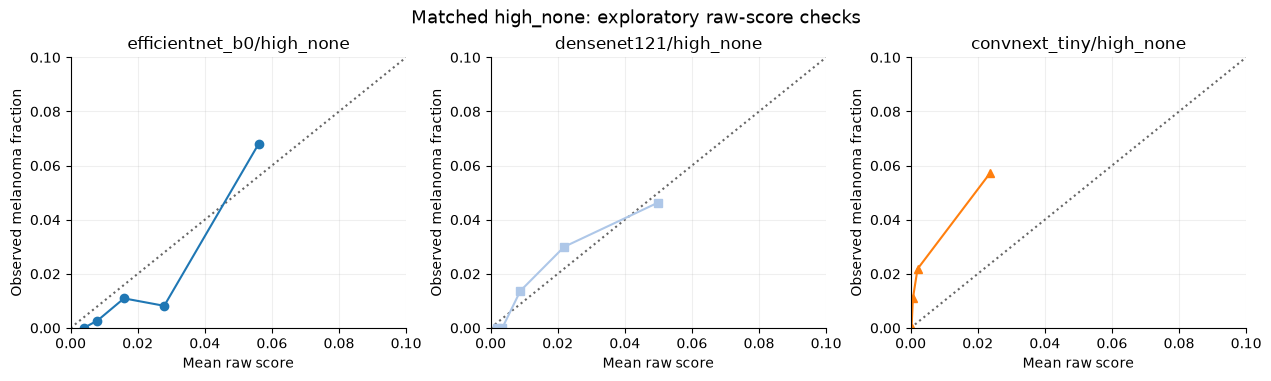

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,pipeline_id
0,1,367,0,0.003893,0.000000,0.001476,0.005676,37,efficientnet_b0/high_none
1,2,367,1,0.008010,0.002725,0.005686,0.010791,68,efficientnet_b0/high_none
2,3,366,4,0.015912,0.010929,0.010804,0.021587,78,efficientnet_b0/high_none
3,4,367,3,0.027895,0.008174,0.021601,0.034557,87,efficientnet_b0/high_none
4,5,367,25,0.056087,0.068120,0.034652,0.220570,77,efficientnet_b0/high_none
5,1,367,0,0.001818,0.000000,0.001069,0.002343,35,densenet121/high_none
6,2,367,0,0.003480,0.000000,0.002349,0.005393,57,densenet121/high_none
7,3,366,5,0.008835,0.013661,0.005413,0.013466,89,densenet121/high_none
8,4,367,11,0.021913,0.029973,0.013554,0.031825,86,densenet121/high_none
9,5,367,17,0.049903,0.046322,0.031871,0.095705,76,densenet121/high_none


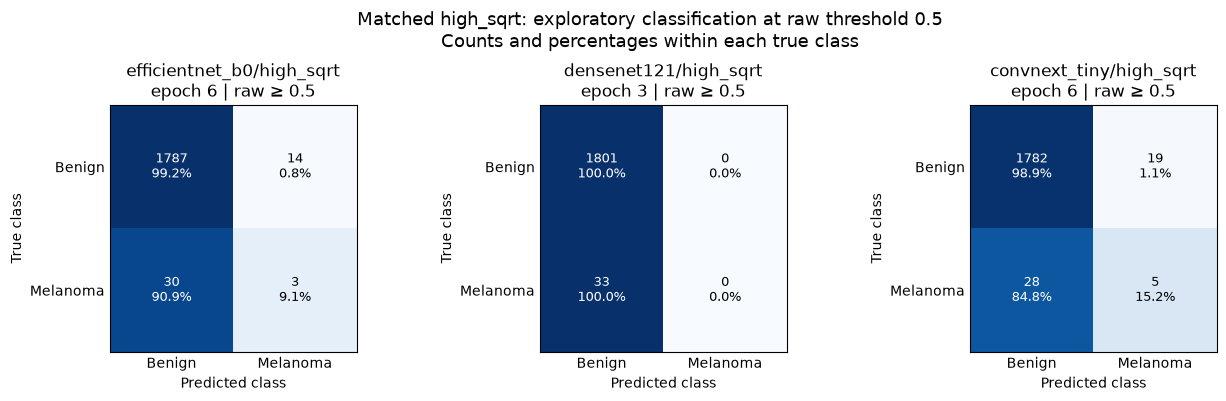

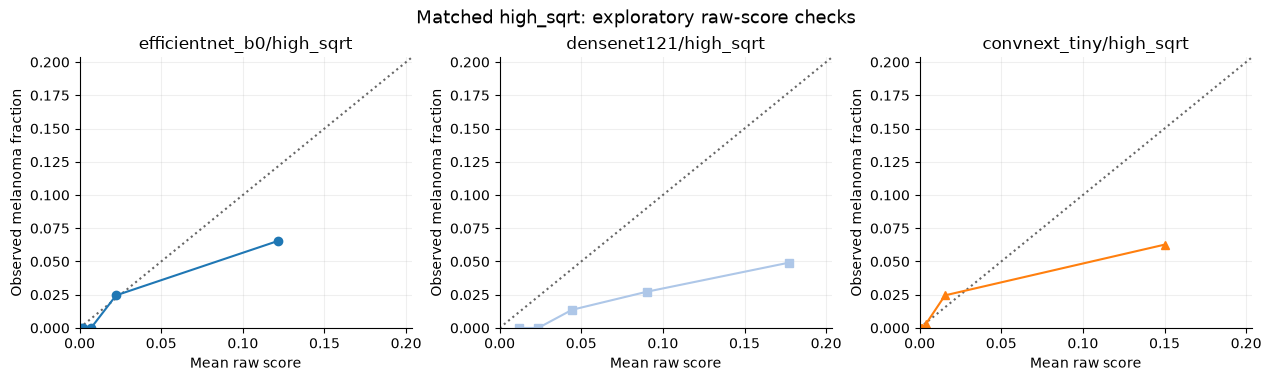

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,pipeline_id
0,1,367,0,0.000941,0.000000,0.000233,0.001392,36,efficientnet_b0/high_sqrt
1,2,367,0,0.002102,0.000000,0.001397,0.003288,53,efficientnet_b0/high_sqrt
2,3,366,0,0.007013,0.000000,0.003289,0.012499,82,efficientnet_b0/high_sqrt
3,4,367,9,0.022358,0.024523,0.012525,0.034486,86,efficientnet_b0/high_sqrt
4,5,367,24,0.121412,0.065395,0.034642,0.806844,81,efficientnet_b0/high_sqrt
5,1,367,0,0.012146,0.000000,0.006575,0.016516,38,densenet121/high_sqrt
6,2,367,0,0.023614,0.000000,0.016544,0.030899,63,densenet121/high_sqrt
7,3,366,5,0.044378,0.013661,0.030916,0.062530,85,densenet121/high_sqrt
8,4,367,10,0.090198,0.027248,0.062672,0.126206,83,densenet121/high_sqrt
9,5,367,18,0.176982,0.049046,0.126215,0.259389,58,densenet121/high_sqrt


In [7]:
if matched:
    display(metrics[["pipeline_id", "selected_epoch", "threshold", "score_type", "TP", "FP", "TN", "FN",
        "precision", "recall", "sensitivity", "specificity", "f1"]].style.format(
        {name: "{:.4f}" for name in ["precision", "recall", "sensitivity", "specificity", "f1"]}, na_rep="Undefined"))
    for slot in summary["matched_recipe_slots"]:
        paired = {key: frame for key, frame in matched.items() if frame.recipe_slot.iloc[0] == slot}
        confusion = plot_confusion_matrices(paired, epochs=epochs,
            title=f"Matched {slot}: exploratory classification at raw threshold 0.5")
        save_figure(confusion, figures_dir / f"{slot}_confusion_threshold_0_5.png")
        plt.show()
        reliability, bins = plot_raw_reliability(paired, title=f"Matched {slot}: exploratory raw-score checks")
        save_figure(reliability, figures_dir / f"{slot}_raw_reliability.png")
        bins.to_csv(tables_dir / f"{slot}_reliability_support.csv", index=False)
        plt.show()
        display(bins)


## Incomplete records and next steps

The table below lists any completed unmatched trials separately. They cannot
rank families. Paused fits preserve model and training states for compatible
resumption at epoch boundaries; reaching a time budget is not evidence against
their performance. Complete matching comparisons before expanding conclusions.

Next, validate every family with longer training and three inner patient folds.
Choose augmentation and preparation separately for each architecture, then
repeat the complete selection procedure within each outer-training partition.
The current [uncertainty notebook](13_image_uncertainty.ipynb) supplies inference
diagnostics only. Fusion, final outer evaluation, any eligible Swin experiment
and reserved-test evaluation remain separate work.


In [8]:
unmatched = {key: frame for key, frame in predictions.items()
    if key in set(summary["unmatched_completed_trials"])}
if unmatched:
    unmatched_metrics = metric_table(unmatched, threshold=.5, epochs=epochs)
    unmatched_metrics.to_csv(tables_dir / "unmatched_exploratory_records.csv", index=False)
    display(unmatched_metrics)
else:
    print("Unmatched completed new trials: none.")
(report_dir / "reporting_receipt.json").write_text(json.dumps({
    "run_id": summary["run_id"], "training_enabled_in_notebook": TRAIN_ARCHITECTURES,
    "matched_recipe_slots": summary["matched_recipe_slots"], "threshold": .5,
    "threshold_tuned": False, "calibration_fitted": False, "test_loaded": False,
    "status": summary["status"],
    "trial_statuses": {record["pipeline_id"]: record["status"] for record in all_records},
    "reporting_source_sha256": {relative: sha256(PROJECT_ROOT / relative) for relative in [
        "src/melanoma_detection/image_evaluation.py", "src/melanoma_detection/image_reporting.py",
        "scripts/build_image_architecture_notebook.py"]},
    "summary_sha256": sha256(run_dir / "summary.json"),
    "prediction_csv_sha256": {str(Path(record["predictions_file"]).relative_to(PROJECT_ROOT)):
        sha256(record["predictions_file"]) for record in all_records
        if record.get("status") == "complete" and record.get("predictions_file")},
    "figures": sorted(path.name for path in figures_dir.glob("*.png"))}, indent=2), encoding="utf-8")
print("Artifacts:", run_dir)
print("Outer evaluation: not performed | reserved test: not loaded")


Unmatched completed new trials: none.
Artifacts: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\results\image_d1_runs\architecture_pilot_3h_v1
Outer evaluation: not performed | reserved test: not loaded


## Limitations

- Six epochs on one inner split measure early learning rather than final potential.
- Choosing recipes and epochs on these validation labels makes the results optimistic.
- The shared weak preparation controls this comparison; it does not establish each family's best preparation.
- Weighted fitting objectives and raw score scales differ; 0.5 is an untuned reporting cutoff.
- Paused or unmatched trials cannot lose a comparison; short results cannot rule out slower families.
- At this historical pilot's completion, longer confirmation, calibration and full outer evaluation remained pending. The later five-fold B0 results now appear in [notebook 14](14_image_nested_evaluation.ipynb) and [clean notebook 09](../Subset_dedup/09_image_modelling.ipynb); they do not turn this short architecture pilot into a final family comparison. Fusion and reserved-test evaluation remain deferred.


## Summary

The saved comparison shows early ranking, fixed-cutoff errors, reliability and
cost on matching patients. The family observations below are exploratory.
No final architecture is selected; confirming the selection process on independent
outer patients remains necessary.


In [9]:
display(Markdown("**Historical AP selection:** the recorded recommendation/epoch remains unchanged; current ROC summaries do not reselect an image procedure."))
if matched:
    observed = metric_table(matched, threshold=.5, epochs=epochs)
    observed["architecture"] = observed.pipeline_id.str.split("/").str[0]
    family_best = observed.sort_values(["architecture", "average_precision", "selected_epoch", "pipeline_id"],
        ascending=[True, False, True, True]).groupby("architecture", sort=False).head(1)
    family_best = family_best.rename(columns={"pipeline_id": "observed_recipe", "selected_epoch": "best_epoch"})
    print("All eight new trials completed." if summary["comparison_complete"] else
        "Partial comparison: family observations use completed matching slots only.")
    display(family_best[["architecture", "observed_recipe", "best_epoch", "roc_auc", "average_precision"]])
    late = family_best.loc[family_best.best_epoch.ge(5), "architecture"].tolist()
    if late:
        display(Markdown("Best observed epochs are near the six-epoch cap for **" +
            ", ".join(late) + "**. Their late peaks support additional training; they do not establish optimal durations."))
else:
    print("No matching slot completed for all three families; there is no comparative family summary yet.")
if not summary["comparison_complete"]:
    outstanding = ledger.loc[ledger.status.ne("complete"),
        ["pipeline_id", "status", "completed_epochs", "selected_epoch"]]
    display(outstanding)
    display(Markdown("Finish missing or paused matching trials before expanding conclusions. "
        "Budget exhaustion is not evidence against unfinished candidates."))
display(Markdown("Next, independently validate **all three families** with their own recipes, "
    "a **30-epoch cap** and **three inner patient folds**. The cap is a maximum budget, "
    "distinct from the validation-selected best epoch. No longer training starts in this reporting notebook."))
print("No final architecture selected | outer evaluation: not performed | reserved test: not loaded")


**Historical AP selection:** the recorded recommendation/epoch remains unchanged; current ROC summaries do not reselect an image procedure.

All eight new trials completed.


,architecture,observed_recipe,best_epoch,roc_auc,average_precision
11,convnext_tiny,convnext_tiny/high_sqrt,6,0.864183,0.149493
4,densenet121,densenet121/low_none,2,0.772971,0.145206
1,efficientnet_b0,efficientnet_b0/low_sqrt,6,0.866337,0.138318


Best observed epochs are near the six-epoch cap for **convnext_tiny, efficientnet_b0**. Their late peaks support additional training; they do not establish optimal durations.

Next, independently validate **all three families** with their own recipes, a **30-epoch cap** and **three inner patient folds**. The cap is a maximum budget, distinct from the validation-selected best epoch. No longer training starts in this reporting notebook.

No final architecture selected | outer evaluation: not performed | reserved test: not loaded
